# Bellman values and decisions before observing shocks

Family 31. A finite MDP supplies all state, action and transition axes. A scenario tree supplies observed histories. The first action cannot depend on which future branch will occur.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

The standalone script is `docs/math/examples/optimal_control.py` to avoid shadowing the python-control provider.

In [2]:
"""Family 31: exact Bellman, Riccati and nonanticipative stochastic MPC."""
from convexity.math import control

mdp = control.FiniteMDP([[[1., 0.], [0., 1.]], [[0., 1.], [0., 1.]]],
                        [[1., 5.], [0., 0.]], .9, terminal=[False, True])
finite = control.finite_horizon(mdp, 4)
print('Finite-horizon values:', finite.values[:, 0], 'actions:', finite.policy[:, 0])
print('Infinite-horizon values:', control.value_iteration(mdp).values)
print('LQR gain:', control.lqr([[1.]], [[1.]], [[1.]], [[1.]]).gain)
tree = control.ScenarioTree([-1, 0, 0], [1., .5, .5], [[0.], [-1.], [1.]])
plan = control.scenario_mpc(tree, [[1.]], [[1.]], [[0.]], [[1.]], [2.], terminal_cost=[[1.]])
print('MPC first action:', plan.actions[0], 'objective:', plan.objective)


Finite-horizon values: [6.355 5.95  5.5   5.    0.   ] actions: [0 0 0 1]
Infinite-horizon values: [10.  0.]


LQR gain: [[0.61803399]]


MPC first action: [-1.] objective: 3.0


## Horizon effects and the value of information

The stopping-like MDP chooses the immediate reward near the endpoint and continuation over a longer horizon. A scenario-specific first action would be clairvoyant: the constrained tree uses one shared root action.

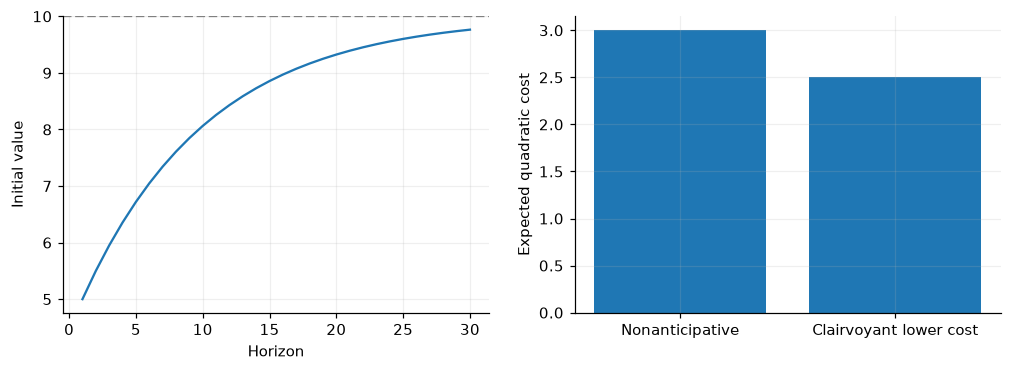

Two-step value with future observation: 1.5
Two-step value without information: 1.0


In [3]:
horizons = np.arange(1, 31)
values = [control.finite_horizon(mdp, int(h)).values[0, 0] for h in horizons]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(horizons, values); axes[0].axhline(10., linestyle='--', color='grey')
axes[0].set(xlabel='Horizon', ylabel='Initial value')
axes[1].bar(['Nonanticipative', 'Clairvoyant lower cost'], [plan.objective, 2.5])
axes[1].set(ylabel='Expected quadratic cost'); plt.show()
observations = np.repeat(np.eye(2)[None, :, :], 2, axis=0)
identity = np.repeat(np.eye(2)[:, None, :], 2, axis=1)
belief_model = control.FiniteMDP(identity, [[1., 0.], [0., 1.]], 1.)
print('Two-step value with future observation:', control.belief_plan(belief_model, observations, [.5, .5], 2).value)
print('Two-step value without information:', control.belief_plan(belief_model, np.ones((2, 2, 1)), [.5, .5], 2).value)

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.